# EVA-X-S on CheXpert dataset

In [1]:
# Prepare the working folders and start the run timer.
import os
import sys
import json
import time
import subprocess
from pathlib import Path

RUN_STARTED = time.time()
WORK = Path('/kaggle/working')
INPUT = Path('/kaggle/input')
WORK.mkdir(parents=True, exist_ok=True)
RUNTIME = WORK / 'eva_x_runtime.py'


In [2]:
# Set the training options and optional input paths.
RUN_TRAINING = True  # False evaluates the released classifier only.
RUN_NAME = 'seed14'
DATA_ROOT = ''  # Leave empty to find the attached CheXpert-v1.0-small dataset.
TRAINED_WEIGHTS = ''  # Optional attached CheXpert fine-tuned checkpoint.
PRETRAINED_WEIGHTS = ''  # Optional attached self-supervised checkpoint.

SEED = 14
TRAIN_INTERVALS = 60  # Official short intervals; these are not full-data epochs.
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.05
LAYER_DECAY = 0.55
MICRO_BATCH = 64
ACCUMULATION = 8  # 64 images x 2 GPUs x 8 = 1,024 images per update.
NUM_WORKERS = 2
EVAL_BATCH = 64
THRESHOLD = 0.5
TIME_BUDGET_HOURS = 4.5
RESUME_TRAINING = True

REPO_COMMIT = 'eedd642c85339b25682ceb574b644cb9afe88e62'
HF_REVISION = '35ddcd6dab6ca99bbdb6cb45c8d1b093aefbd0ee'
REPO = WORK / 'EVA-X-eedd642c'
CODE_DIR = WORK / 'eva_x_official'
RESULTS = WORK / 'eva_x_s_chexpert_results' / RUN_NAME
RESULTS.mkdir(parents=True, exist_ok=True)


In [3]:
# Install the small Python dependencies without replacing PyTorch.
from importlib import metadata

packages = {'timm': '0.9.16', 'einops': '0.8.1', 'huggingface_hub': '0.36.2'}
missing = []
for package, version in packages.items():
    try:
        installed = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f'{package}=={version}')
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
print('Dependencies ready.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.5 MB/s eta 0:00:00
Dependencies ready.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [4]:
# Import the analysis libraries and check the available GPUs.
import gc
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve

warnings.filterwarnings('ignore', message='Overwriting eva02_.*', category=UserWarning)
GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT == 0:
    raise RuntimeError('Enable GPU T4 x2 in Kaggle Session options.')
if RUN_TRAINING and GPU_COUNT != 2:
    raise RuntimeError('This training configuration expects GPU T4 x2.')
torch.manual_seed(SEED)
np.random.seed(SEED)
print('Using:', ', '.join(torch.cuda.get_device_name(i) for i in range(GPU_COUNT)))


Using: Tesla T4, Tesla T4


In [5]:
# Download the pinned official EVA-X source.
if not (REPO / '.git').exists():
    subprocess.run(['git', 'init', '-q', str(REPO)], check=True)
    subprocess.run(['git', '-C', str(REPO), 'remote', 'add', 'origin',
                    'https://github.com/hustvl/EVA-X.git'], check=True)
current = subprocess.run(['git', '-C', str(REPO), 'rev-parse', 'HEAD'],
                         capture_output=True, text=True).stdout.strip()
if current != REPO_COMMIT:
    subprocess.run(['git', '-C', str(REPO), 'fetch', '-q', '--depth', '1',
                    'origin', REPO_COMMIT], check=True)
    subprocess.run(['git', '-C', str(REPO), 'checkout', '-q', '--detach', REPO_COMMIT], check=True)
CODE_DIR.mkdir(exist_ok=True)
print('Official source:', REPO_COMMIT[:12])


Official source: eedd642c8533


In [6]:
%%writefile {CODE_DIR / 'kaggle_ops.py'}
# Save the PyTorch equivalents of the official fused operations
import types
import torch
from torch import nn
from torch.nn import functional as F


class TorchSwiGLU(nn.Module):
    def __init__(self, in_features, hidden_features, out_features=None, bias=True, **kwargs):
        super().__init__()
        out_features = out_features or in_features
        self.w12 = nn.Linear(in_features, 2 * hidden_features, bias=bias)
        self.w3 = nn.Linear(hidden_features, out_features, bias=bias)

    def forward(self, x):
        x1, x2 = self.w12(x).chunk(2, dim=-1)
        return self.w3(F.silu(x1) * x2)


def memory_efficient_attention(q, k, v):
    output = F.scaled_dot_product_attention(q.transpose(1, 2), k.transpose(1, 2),
                                           v.transpose(1, 2), dropout_p=0.)
    return output.transpose(1, 2).contiguous()


xops = types.SimpleNamespace(SwiGLU=TorchSwiGLU, memory_efficient_attention=memory_efficient_attention)


Writing /kaggle/working/eva_x_official/kaggle_ops.py


In [7]:
%%writefile {RUNTIME}
# Save the official-source compatibility helpers
import ast
import contextlib
import copy
import hashlib
import importlib.util
import io
import json
import math
import os
import random
import re
import sys
import time
import types
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import average_precision_score, precision_recall_fscore_support, roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Pleural Effusion']
MODEL_NAME = 'eva02_small_patch16_xattn_fusedLN_SwiGLU_preln_RoPE'


def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


def prepare_official_code(repo, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    (destination / '__init__.py').write_text('')
    source = (Path(repo) / 'classification/models/models_eva.py').read_text()
    replacements = {
        'import xformers.ops as xops': 'from .kaggle_ops import xops',
        'from apex.normalization import FusedLayerNorm': 'from torch.nn import LayerNorm as FusedLayerNorm',
    }
    for before, after in replacements.items():
        if source.count(before) != 1:
            raise RuntimeError('The pinned EVA-X source does not match the compatibility patch.')
        source = source.replace(before, after)
    (destination / 'models_eva.py').write_text(source)
    (destination / 'rope.py').write_text((Path(repo) / 'classification/models/rope.py').read_text())
    source = (Path(repo) / 'classification/utils/dataloader_med.py').read_text()
    node = next(n for n in ast.parse(source).body if isinstance(n, ast.ClassDef) and n.name == 'CheXpert')
    dataset_source = ast.get_source_segment(source, node)
    # Explicit assignments retain upstream label values with pandas 2/3 Copy-on-Write.
    dataset_source = re.sub(r"self\.df\[col\]\.replace\(([^\n]*?),\s*inplace=True\)",
                            r"self.df[col] = self.df[col].replace(\1)", dataset_source)
    dataset_source = re.sub(r"self\.df\[col\]\.fillna\(([^\n]*?),\s*inplace=True\)",
                            r"self.df[col] = self.df[col].fillna(\1)", dataset_source)
    imports = 'import random\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom PIL import Image\nfrom torch.utils.data import Dataset\n'
    (destination / 'chexpert.py').write_text(imports + dataset_source + '\n')
    (destination / 'lr_decay.py').write_text((Path(repo) / 'classification/utils/lr_decay.py').read_text())
    return {'architecture': 'official source with PyTorch kernel substitutions',
            'dataset': 'official CheXpert class; explicit pandas assignments; unchanged sampling',
            'optimizer_groups': 'official layer-wise decay implementation'}


Writing /kaggle/working/eva_x_runtime.py


In [8]:
%%writefile -a {RUNTIME}
# Save the dataset and transform helpers
def image_transform():
    return transforms.Compose([
        transforms.Resize(256, interpolation=InterpolationMode.BICUBIC),
        transforms.CenterCrop(224), transforms.ToTensor(),
        transforms.Normalize((0.49185243,) * 3, (0.28509309,) * 3),
    ])


def import_official(code_dir):
    code_dir = Path(code_dir)
    sys.path.insert(0, str(code_dir.parent))
    package = code_dir.name
    importlib.import_module(package)
    with contextlib.redirect_stdout(io.StringIO()):
        models = importlib.import_module(package + '.models_eva')
    data = importlib.import_module(package + '.chexpert')
    decay = importlib.import_module(package + '.lr_decay')
    return models, data, decay


def make_dataset(cfg, split):
    _, data, _ = import_official(cfg['code_dir'])
    with contextlib.redirect_stdout(io.StringIO()):
        dataset = data.CheXpert(
            csv_path=cfg['train_csv'] if split == 'train' else cfg['valid_csv'],
            image_root_path=str(Path(cfg['data_root'])) + os.sep,
            use_frontal=True, use_upsampling=False, mode='train' if split == 'train' else 'valid',
            class_index=-1, transform=image_transform(), verbose=False,
            use_rand_label=False, seed=123,
        )
    labels = np.asarray(dataset._labels_list)
    if labels.ndim != 2 or labels.shape[1] != 5 or not np.isin(labels, [0, 1]).all():
        raise ValueError('Unexpected label shape or unresolved uncertain labels.')
    return dataset


Appending to /kaggle/working/eva_x_runtime.py


In [9]:
%%writefile -a {RUNTIME}
# Save the checkpoint-loading helper
def make_model(cfg, checkpoint_path, training=False):
    models, _, _ = import_official(cfg['code_dir'])
    with contextlib.redirect_stdout(io.StringIO()):
        model = getattr(models, MODEL_NAME)(num_classes=5, img_size=224,
            use_mean_pooling=True, drop_path_rate=0.15 if training else 0.,
            drop_rate=0., attn_drop_rate=0., use_checkpoint=False, stop_grad_conv1=False)
    # Files must match the verified public-release hashes before trusted loading
    path = str(checkpoint_path)
    expected = cfg.get('checkpoint_hashes', {}).get(Path(path).name)
    if expected and sha256(path) != expected:
        raise ValueError('Checkpoint checksum does not match the official release.')
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    state = checkpoint.get('model', checkpoint.get('module', checkpoint))
    state = {k.removeprefix('module.'): v for k, v in state.items()}
    if training:
        for key in ['head.weight', 'head.bias']:
            if key in state and state[key].shape != model.state_dict()[key].shape:
                state.pop(key)
        # The MIM-only mask, token predictor, and final norm are absent downstream
        for key in ['mask_token', 'lm_head.weight', 'lm_head.bias', 'norm.weight', 'norm.bias']:
            if key not in model.state_dict():
                state.pop(key, None)
    status = model.load_state_dict(state, strict=False)
    allowed = {'head.weight', 'head.bias', 'fc_norm.weight', 'fc_norm.bias'} if training else set()
    if set(status.missing_keys) - allowed or status.unexpected_keys:
        raise RuntimeError(f'Unexpected checkpoint keys: {status}')
    return model


Appending to /kaggle/working/eva_x_runtime.py


In [10]:
%%writefile -a {RUNTIME}
# Save the prediction and metric helpers
def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(seed)
    random.seed(seed)


def amp_context(device):
    return torch.autocast(device_type='cuda', dtype=torch.float16) if device.type == 'cuda' else contextlib.nullcontext()


def sync(device):
    if device.type == 'cuda':
        torch.cuda.synchronize(device)


@torch.inference_mode()
def predict(model, dataset, device, batch_size=64, workers=2):
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=workers,
                        pin_memory=device.type == 'cuda', worker_init_fn=seed_worker,
                        generator=torch.Generator().manual_seed(0))
    logits, truths = [], []
    sync(device)
    start = time.perf_counter()
    for images, target in loader:
        with amp_context(device):
            output = model(images.to(device, non_blocking=True))
        logits.append(output.float().cpu())
        truths.append(target)
    sync(device)
    logits = torch.cat(logits)
    truth = torch.cat(truths).numpy()
    if not torch.isfinite(logits).all():
        raise RuntimeError('Non-finite model predictions.')
    return truth, logits.sigmoid().numpy(), float(nn.functional.binary_cross_entropy_with_logits(
        logits, torch.from_numpy(truth))), time.perf_counter() - start


def classification_metrics(truth, probs, threshold=0.5):
    rows = []
    for i, label in enumerate(LABELS):
        y, score = truth[:, i], probs[:, i]
        pred = score >= threshold
        precision, recall, f1, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
        both_classes = len(np.unique(y)) == 2
        rows.append(dict(label=label, AUROC=roc_auc_score(y, score) if both_classes else np.nan,
            AP=average_precision_score(y, score) if y.sum() else np.nan,
            accuracy=float((pred == y).mean()), precision=precision, recall=recall,
            F1=f1, threshold=threshold, positives=int(y.sum()), images=len(y)))
    return pd.DataFrame(rows).set_index('label')


Appending to /kaggle/working/eva_x_runtime.py


In [11]:
%%writefile -a {RUNTIME}
# Save the result and resume helpers
def save_evaluation(cfg, name, dataset, truth, probs, loss, seconds):
    result = Path(cfg['results']) / name
    result.mkdir(exist_ok=True, parents=True)
    metrics = classification_metrics(truth, probs, cfg['threshold'])
    metrics.to_csv(result / 'metrics.csv')
    frame = dataset.df[['Path']].reset_index(drop=True).copy()
    for i, label in enumerate(LABELS):
        frame[label + '_truth'] = truth[:, i].astype(int)
        frame[label + '_probability'] = probs[:, i]
        frame[label + '_prediction'] = (probs[:, i] >= cfg['threshold']).astype(int)
    frame.to_csv(result / 'predictions.csv', index=False)
    macro = float(metrics.AUROC.mean()) if metrics.AUROC.notna().all() else None
    (result / 'summary.json').write_text(json.dumps({'macro_AUROC': macro,
        'public_validation_BCE': loss, 'inference_seconds': seconds,
        'threshold': cfg['threshold'], 'images': len(frame)}, indent=2))
    return metrics


def capture_rng():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state() if torch.cuda.is_available() else None)


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    if torch.cuda.is_available() and state['cuda'] is not None:
        torch.cuda.set_rng_state(state['cuda'])


def training_signature(cfg):
    keys = ['seed', 'intervals', 'learning_rate', 'weight_decay', 'layer_decay',
            'train_csv', 'valid_csv', 'data_root', 'repo_commit', 'micro_batch',
            'accumulation', 'world_size', 'ssl_checkpoint', 'checkpoint_hashes']
    return {key: cfg[key] for key in keys}


def atomic_save(payload, path):
    temporary = Path(str(path) + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


Appending to /kaggle/working/eva_x_runtime.py


In [12]:
%%writefile -a {RUNTIME}
# Save the gradient-accumulation training step
def train_interval(model, loader, optimizer, scaler, device, accumulation, log_progress=False):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    # Match the reference number of complete global-batch updates per interval.
    used_batches = len(loader) // accumulation * accumulation
    if used_batches == 0:
        raise ValueError('No complete optimizer step; check dataset and batch settings.')
    total_loss, total_samples, updates = 0., 0, 0
    sync(device)
    started = time.perf_counter()
    iterator = iter(loader)
    for index in range(used_batches):
        images, labels = next(iterator)
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        is_update = (index + 1) % accumulation == 0
        no_sync = model.no_sync() if hasattr(model, 'no_sync') and not is_update else contextlib.nullcontext()
        with no_sync:
            with amp_context(device):
                logits = model(images)
                loss = nn.functional.binary_cross_entropy_with_logits(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite training loss; a checkpoint was not overwritten.')
            scaler.scale(loss / accumulation).backward()
        if is_update:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            updates += 1
            if updates == 1 and log_progress:
                print('First optimizer step completed.', flush=True)
        total_loss += loss.detach().double() * len(labels)
        total_samples += len(labels)
    sync(device)
    return float(total_loss), total_samples, updates, time.perf_counter() - started


Appending to /kaggle/working/eva_x_runtime.py


In [13]:
%%writefile -a {RUNTIME}
# Save the distributed fine-tuning runner
def run_training(cfg):
    import torch.distributed as dist
    from torch.nn.parallel import DistributedDataParallel
    from torch.utils.data.distributed import DistributedSampler

    rank, local_rank = int(os.environ.get('RANK', 0)), int(os.environ.get('LOCAL_RANK', 0))
    world = int(os.environ.get('WORLD_SIZE', 1))
    cuda = torch.cuda.is_available()
    device = torch.device('cuda', local_rank) if cuda else torch.device('cpu')
    if cuda:
        torch.cuda.set_device(device)
    torch.set_num_threads(1)
    if world > 1:
        dist.init_process_group(backend='nccl' if cuda else 'gloo')
    seed = cfg['seed'] + rank
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    train_data, valid_data = make_dataset(cfg, 'train'), make_dataset(cfg, 'valid')
    model = make_model(cfg, cfg['ssl_checkpoint'], training=True).to(device)
    _, _, decay = import_official(cfg['code_dir'])
    groups = decay.param_groups_lrd(model, cfg['weight_decay'], model.no_weight_decay(), cfg['layer_decay'])
    for group in groups:
        group['lr'] = cfg['learning_rate'] * group['lr_scale']
    optimizer = torch.optim.AdamW(groups, lr=cfg['learning_rate'])
    scaler = torch.amp.GradScaler('cuda', enabled=cuda)
    run_dir = Path(cfg['results']) / 'finetuned'
    run_dir.mkdir(exist_ok=True)
    last_file, best_file = run_dir / 'last.pth', run_dir / 'best.pth'
    start_interval, best_auc, history, training_seconds = 0, -math.inf, [], 0.
    signature = training_signature(cfg)
    pending_rng = None
    if cfg['resume'] and last_file.exists():
        state = torch.load(last_file, map_location='cpu', weights_only=False)
        if state['signature'] != signature:
            raise ValueError('Existing training configuration differs. Change RUN_NAME or disable resume.')
        model.load_state_dict(state['model'], strict=True)
        optimizer.load_state_dict(state['optimizer'])
        scaler.load_state_dict(state['scaler'])
        start_interval, best_auc = state['next_interval'], state['best_auc']
        history, training_seconds = state['history'], state['training_seconds']
        pending_rng = state['rng_states'][rank]
    elif last_file.exists():
        raise FileExistsError('A training run exists. Enable resume or change RUN_NAME.')
    if world > 1:
        model = DistributedDataParallel(model, device_ids=[local_rank] if cuda else None,
                                        find_unused_parameters=False)
    base_model = model.module if hasattr(model, 'module') else model
    sampler = DistributedSampler(train_data, num_replicas=world, rank=rank, shuffle=True, seed=0)
    if pending_rng is not None:
        restore_rng(pending_rng)
    if rank == 0:
        print(f'Training {sum(p.numel() for p in base_model.parameters()):,} parameters on {world} device(s).', flush=True)
        print(f'Released sampling: {len(train_data):,} draws/interval; {10 * len(train_data):,} eligible training rows.', flush=True)
    session_started = time.perf_counter()
    for interval in range(start_interval, cfg['intervals']):
        interval_started = time.perf_counter()
        sampler.set_epoch(interval)
        generator = torch.Generator().manual_seed(cfg['seed'] + rank * 10000 + interval)
        loader = DataLoader(train_data, batch_size=cfg['micro_batch'], sampler=sampler,
            num_workers=cfg['workers'], pin_memory=cuda, drop_last=True,
            worker_init_fn=seed_worker, generator=generator)
        loss_sum, samples, updates, train_time = train_interval(model, loader, optimizer, scaler,
            device, cfg['accumulation'], log_progress=rank == 0 and interval == start_interval)
        del loader
        totals = torch.tensor([loss_sum, samples], device=device, dtype=torch.float64)
        if world > 1:
            dist.all_reduce(totals)
        train_loss = (totals[0] / totals[1]).item()
        rng = capture_rng()
        rng_states = [None] * world if rank == 0 else None
        if world > 1:
            dist.gather_object(rng, rng_states, dst=0)
        else:
            rng_states = [rng]
        stop = torch.zeros(1, device=device, dtype=torch.int32)
        if rank == 0:
            y, probs, val_loss, eval_seconds = predict(base_model, valid_data, device,
                                                       cfg['eval_batch'], cfg['workers'])
            metrics = classification_metrics(y, probs, cfg['threshold'])
            auc = float(metrics.AUROC.mean()) if metrics.AUROC.notna().all() else float('nan')
            if not math.isfinite(auc):
                raise ValueError('Public-validation AUROC is undefined; inspect its labels.')
            training_seconds += train_time
            row = dict(interval=interval + 1, train_loss=train_loss, public_val_loss=val_loss,
                public_val_AUROC=auc, seconds=time.perf_counter() - interval_started,
                train_seconds=train_time, evaluation_seconds=eval_seconds,
                global_samples=int(totals[1]), optimizer_steps=updates)
            history.append(row)
            improved = auc >= best_auc
            best_auc = max(best_auc, auc)
            payload = dict(model=base_model.state_dict(), optimizer=optimizer.state_dict(),
                scaler=scaler.state_dict(), next_interval=interval + 1, best_auc=best_auc,
                history=history, training_seconds=training_seconds, rng_states=rng_states,
                signature=signature, label_order=LABELS)
            atomic_save(payload, last_file)
            if improved:
                atomic_save(dict(model=base_model.state_dict(), interval=interval + 1,
                                 macro_AUROC=auc, label_order=LABELS), best_file)
            pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
            elapsed = time.perf_counter() - session_started
            remaining = (cfg['intervals'] - interval - 1) * elapsed / (interval - start_interval + 1)
            print(f'Interval {interval+1:02d}/{cfg["intervals"]} | train {train_loss:.4f} | '
                  f'public val {val_loss:.4f} | AUROC {auc:.3f} | {row["seconds"]:.0f}s | '
                  f'ETA {remaining/60:.0f} min', flush=True)
            if time.time() >= cfg['deadline_unix']:
                stop.fill_(1)
        if world > 1:
            dist.broadcast(stop, src=0)
        if stop.item():
            if rank == 0:
                print('Time budget reached; last.pth can resume this incomplete run.', flush=True)
            break
    if rank == 0:
        complete = len(history) >= cfg['intervals']
        summary = dict(completed=complete, completed_intervals=len(history),
            planned_intervals=cfg['intervals'], best_public_validation_AUROC=best_auc,
            training_seconds=training_seconds, session_seconds=time.perf_counter()-session_started,
            evaluation_seconds=sum(row['evaluation_seconds'] for row in history))
        (run_dir / 'training_summary.json').write_text(json.dumps(summary, indent=2))
        print(f'Training time: {training_seconds/60:.1f} min | completed {len(history)}/{cfg["intervals"]} intervals.', flush=True)
    if world > 1:
        dist.destroy_process_group()


Appending to /kaggle/working/eva_x_runtime.py


In [14]:
# Prepare and import the official model, dataset, and optimizer groups
sys.path.insert(0, str(WORK))
import eva_x_runtime as eva

compatibility = eva.prepare_official_code(REPO, CODE_DIR)
LABELS = eva.LABELS
print('EVA-X-S architecture ready.')


EVA-X-S architecture ready.


In [15]:
# Find the CheXpert CSV files without scanning every image directory
def input_files(filename):
    for folder, directories, files in os.walk(INPUT):
        directories[:] = [d for d in directories if d not in {'train', 'valid', 'test', 'images'}]
        if filename in files:
            yield Path(folder) / filename

if DATA_ROOT:
    csv_root = Path(DATA_ROOT)
else:
    choices = [p.parent for p in input_files('valid.csv') if (p.parent / 'train.csv').is_file()]
    if len(choices) != 1:
        raise FileNotFoundError('Attach one CheXpert dataset, or enter DATA_ROOT explicitly.')
    csv_root = choices[0]
if not all((csv_root / f'{split}.csv').is_file() for split in ['train', 'valid']):
    raise FileNotFoundError('DATA_ROOT must contain train.csv and valid.csv.')


In [16]:
# Resolve image paths while preserving the original CSV labels
tables = {split: pd.read_csv(csv_root / f'{split}.csv') for split in ['train', 'valid']}
for split, frame in tables.items():
    if not set(['Path', 'Frontal/Lateral', *LABELS]).issubset(frame.columns):
        raise ValueError('The attached CSV does not match the CheXpert format.')
    def relative_path(value):
        parts = Path(value).parts
        if split not in parts:
            raise ValueError(f'Cannot resolve image path: {value}')
        return str(Path(*parts[parts.index(split):]))
    frame['Path'] = frame['Path'].map(relative_path)
roots = [csv_root, csv_root / 'CheXpert-v1.0-small', csv_root / 'CheXpert-v1.0']
matching = [root for root in roots if all((root / frame.Path.iloc[0]).is_file() for frame in tables.values())]
if len(matching) != 1:
    raise FileNotFoundError('Image directories do not match the CSV paths; check DATA_ROOT.')
image_root = matching[0]
for split, frame in tables.items():
    frame.to_csv(RESULTS / f'{split}_source.csv', index=False)
cfg = dict(code_dir=str(CODE_DIR), results=str(RESULTS), data_root=str(image_root),
           train_csv=str(RESULTS / 'train_source.csv'), valid_csv=str(RESULTS / 'valid_source.csv'),
           threshold=THRESHOLD)


In [17]:
# Verify frontal images and patient separation with the official loader
train_data = eva.make_dataset(cfg, 'train')
valid_data = eva.make_dataset(cfg, 'valid')
for name, dataset in [('Train', train_data), ('Public validation', valid_data)]:
    missing = next((p for p in dataset._images_list if not Path(p).is_file()), None)
    if missing:
        raise FileNotFoundError(f'Missing {name} image: {missing}')
    print(f'{name}: {dataset._num_images:,} frontal images')
train_patients = set(train_data.df.Path.str.extract(r'(patient\d+)', expand=False).dropna())
valid_patients = set(valid_data.df.Path.str.extract(r'(patient\d+)', expand=False).dropna())
if not train_patients or not valid_patients or train_patients & valid_patients:
    raise ValueError('Patient identifiers are missing or overlap across the two source splits.')
train_data.df.iloc[:10 * len(train_data)][['Path', *LABELS]].to_csv(
    RESULTS / 'eligible_training_rows.csv', index=False)


Train: 191,027 frontal images
Public validation: 202 frontal images


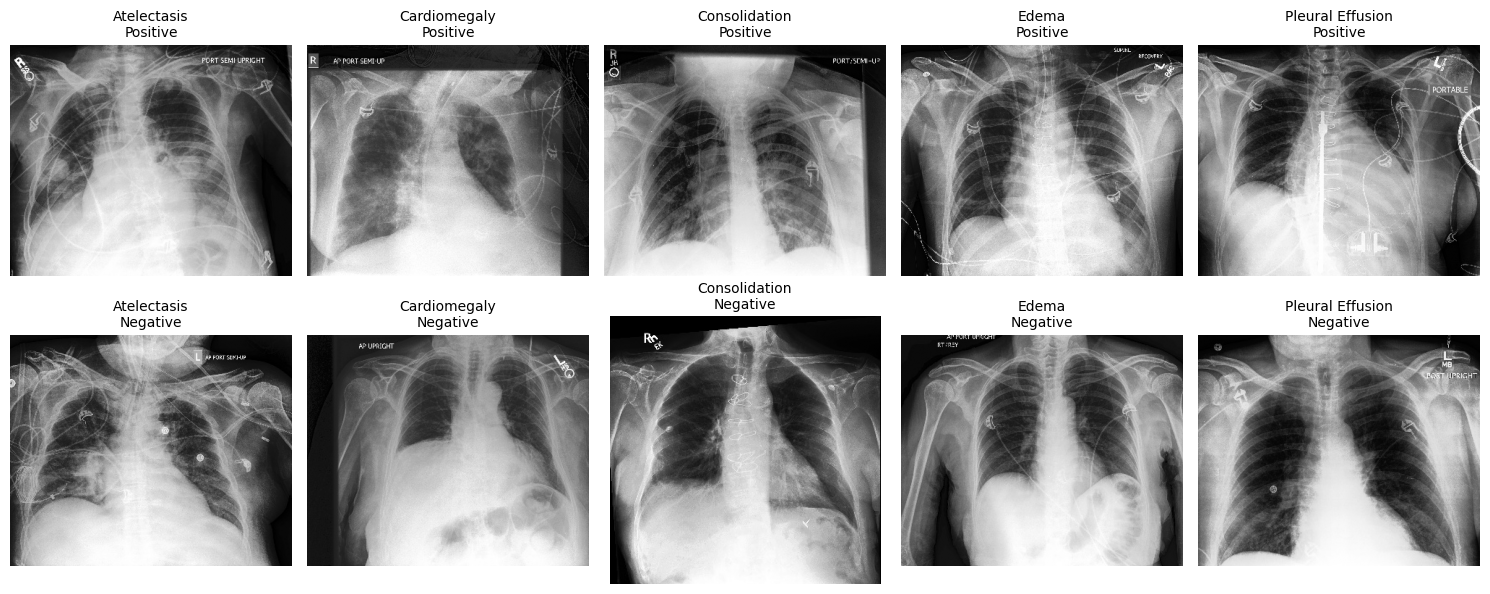

In [18]:
# Show one positive and one negative training image for each finding
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for column, label in enumerate(LABELS):
    for row, target in enumerate([1, 0]):
        examples = train_data.df[train_data.df[label] == target]
        ax = axes[row, column]
        if not examples.empty:
            sample = examples.sample(1, random_state=SEED).iloc[0]
            with Image.open(image_root / sample.Path) as image:
                ax.imshow(image.convert('L'), cmap='gray')
        ax.set_title(f'{label}\n' + ('Positive' if target else 'Negative'), fontsize=10)
        ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [19]:
# Locate or download the verified public model checkpoints
import requests

HASHES = {
    'eva_x_small_patch16_merged520k_mim_chexpert_ft.pth':
        '1a5b63570ca4094c1118018e44d3012a95b904132942a8edb2fc0e5dc8aa0e97',
    'eva_x_small_patch16_merged520k_mim.pt':
        '135d70a6988b5aacfe4848e1c2a0d524b2c076536fcaccdce88b636d302316c2',
}
def get_checkpoint(filename, explicit=''):
    if explicit and not Path(explicit).is_file():
        raise FileNotFoundError(f'Checkpoint path does not exist: {explicit}')
    attached = list(input_files(filename)) if not explicit else [Path(explicit)]
    destination = attached[0] if attached else WORK / 'eva_x_checkpoints' / filename
    if not destination.is_file():
        print('Downloading:', filename, flush=True)
        destination.parent.mkdir(exist_ok=True)
        temporary = destination.with_suffix(destination.suffix + '.part')
        url = f'https://huggingface.co/MapleF/eva_x/resolve/{HF_REVISION}/{filename}'
        with requests.get(url, stream=True, timeout=(20, 90)) as response:
            response.raise_for_status()
            with temporary.open('wb') as stream:
                for chunk in response.iter_content(8 * 1024 * 1024):
                    stream.write(chunk)
        temporary.replace(destination)
    if eva.sha256(destination) != HASHES[filename]:
        raise ValueError(f'Checkpoint checksum mismatch: {destination}')
    print('Verified:', filename)
    return str(destination)

reference_checkpoint = get_checkpoint(next(iter(HASHES)), TRAINED_WEIGHTS)
ssl_checkpoint = get_checkpoint('eva_x_small_patch16_merged520k_mim.pt', PRETRAINED_WEIGHTS) if RUN_TRAINING else ''


Downloading: eva_x_small_patch16_merged520k_mim_chexpert_ft.pth
Verified: eva_x_small_patch16_merged520k_mim_chexpert_ft.pth
Downloading: eva_x_small_patch16_merged520k_mim.pt
Verified: eva_x_small_patch16_merged520k_mim.pt


In [20]:
# Save the configuration 
cfg.update(seed=SEED, intervals=TRAIN_INTERVALS, learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY, micro_batch=MICRO_BATCH,
    accumulation=ACCUMULATION, workers=NUM_WORKERS, eval_batch=EVAL_BATCH,
    world_size=GPU_COUNT, ssl_checkpoint=ssl_checkpoint, reference_checkpoint=reference_checkpoint,
    checkpoint_hashes=HASHES, repo_commit=REPO_COMMIT, hf_revision=HF_REVISION,
    deadline_unix=RUN_STARTED + TIME_BUDGET_HOURS * 3600, resume=RESUME_TRAINING,
    run_training=RUN_TRAINING, label_order=LABELS, compatibility=compatibility)
protocol = {
    'reference_macro_AUROC': 0.901,
    'benchmark': 'CheXpert public validation; frontal images; five findings',
    'training': 'Full encoder and head; self-supervised initialization; 60 released short intervals',
    'sampling': 'Upstream N//20 length and ten-block random offset retained; only about half of shuffled training rows eligible',
    'selection': 'Best public-validation AUROC, as in the release; not an independent test estimate',
    'duration': 'Checkpoint metadata confirms 60 intervals; README says five epochs; supplement is inconsistent',
    'hardware': 'Two T4 GPUs with gradient accumulation instead of four RTX 3090 GPUs',
    'threshold': 'Fixed 0.5 for supplementary binary metrics; no tuning on public validation',
    'numerics': 'PyTorch SDPA, packed SwiGLU and LayerNorm replace CUDA dependencies; GPU bitwise equivalence not claimed',
    'resume': 'Save optimizer, scaler and per-rank RNG; worker generator reset deterministically each interval',
}
(RESULTS / 'config.json').write_text(json.dumps(cfg, indent=2))
(RESULTS / 'protocol.json').write_text(json.dumps(protocol, indent=2))
print(f'Fine-tuning: {RUN_TRAINING} | LR {LEARNING_RATE} | {TRAIN_INTERVALS} short intervals | '
      f'effective batch {MICRO_BATCH * GPU_COUNT * ACCUMULATION}')


Fine-tuning: True | LR 0.001 | 60 short intervals | effective batch 1024


In [21]:
# Load the released CheXpert classifier with its trained five-label head
device = torch.device('cuda:0')
load_start = time.perf_counter()
reference_model = eva.make_model(cfg, reference_checkpoint).to(device).eval()
eva.sync(device)
checkpoint_load_seconds = time.perf_counter() - load_start
print(f'Loaded official classifier: {sum(p.numel() for p in reference_model.parameters()):,} parameters')


Loaded official classifier: 21,669,125 parameters


In [22]:
# Evaluate the released classifier on the public validation images.
truth, reference_probs, reference_loss, reference_seconds = eva.predict(
    reference_model, valid_data, device, EVAL_BATCH, NUM_WORKERS)
reference_metrics = eva.save_evaluation(cfg, 'reference', valid_data, truth,
                                        reference_probs, reference_loss, reference_seconds)
print(reference_metrics[['AUROC', 'AP', 'accuracy', 'precision', 'recall', 'F1']].round(3).to_string())
print(f'Released-checkpoint macro AUROC: {reference_metrics.AUROC.mean():.3f} '
      f'| published reference: 0.901 | inference: {reference_seconds:.1f}s')
del reference_model
gc.collect()
torch.cuda.empty_cache()


                  AUROC     AP  accuracy  precision  recall     F1
label                                                             
Atelectasis       0.846  0.717     0.738      0.750   0.440  0.555
Cardiomegaly      0.839  0.775     0.728      0.923   0.182  0.304
Consolidation     0.944  0.734     0.842      0.000   0.000  0.000
Edema             0.936  0.803     0.881      0.688   0.786  0.733
Pleural Effusion  0.942  0.886     0.871      0.797   0.797  0.797
Released-checkpoint macro AUROC: 0.901 | published reference: 0.901 | inference: 2.6s


In [23]:
%%writefile {WORK / 'eva_x_train.py'}
# Start the training worker with the saved configuration
import json
import sys
from eva_x_runtime import run_training

if __name__ == '__main__':
    with open(sys.argv[1]) as stream:
        run_training(json.load(stream))


Writing /kaggle/working/eva_x_train.py


In [24]:
# Fine-tune the complete encoder and head using the released training profile
worker_file = WORK / 'eva_x_train.py'
training_wall_seconds = 0.
setup_and_reference_seconds = time.time() - RUN_STARTED
if RUN_TRAINING:
    print('Training uses the released short-interval sampler; protocol.json records its limitations.', flush=True)
    train_start = time.perf_counter()
    environment = os.environ.copy()
    environment['OMP_NUM_THREADS'] = '1'
    environment['PYTHONUNBUFFERED'] = '1'
    import socket
    with socket.socket() as listener:
        listener.bind(('127.0.0.1', 0))
        port = listener.getsockname()[1]
    command = [sys.executable, '-m', 'torch.distributed.run', '--nnodes=1',
               '--master_addr=127.0.0.1', f'--master_port={port}',
               f'--nproc_per_node={GPU_COUNT}', str(worker_file), str(RESULTS / 'config.json')]
    with (RESULTS / 'training.log').open('a', buffering=1) as log:
        process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1, env=environment, cwd=WORK)
        for line in process.stdout:
            print(line, end='', flush=True)
            log.write(line)
        return_code = process.wait()
    training_wall_seconds = time.perf_counter() - train_start
    if return_code:
        raise RuntimeError('Fine-tuning failed; inspect training.log before continuing.')
else:
    print('Evaluation-only run; no training curves will be generated.')


Training uses the released short-interval sampler; protocol.json records its limitations.
/kaggle/working/eva_x_official/models_eva.py:797: UserWarning: Overwriting eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE in registry with eva_x_official.models_eva.eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
/kaggle/working/eva_x_official/models_eva.py:797: UserWarning: Overwriting eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE in registry with eva_x_official.models_eva.eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
Training 21,669,125 parameters on 2 device(s).
Released sampling: 9,551 draws/interval; 95,510 eligible training rows.
First optimizer step completed.
Interval 01/60 | train 0.5673 | pub

In [25]:
# Evaluate our best fine-tuned model separately from the released classifier
selected_name = 'reference'
selected_probs = reference_probs
selected_metrics = reference_metrics
if RUN_TRAINING:
    own_checkpoint = RESULTS / 'finetuned' / 'best.pth'
    if not own_checkpoint.is_file():
        raise FileNotFoundError('No fine-tuned checkpoint was saved.')
    model = eva.make_model(cfg, own_checkpoint).to(device).eval()
    own_truth, selected_probs, own_loss, own_seconds = eva.predict(
        model, valid_data, device, EVAL_BATCH, NUM_WORKERS)
    if not np.array_equal(truth, own_truth):
        raise ValueError('Evaluation row order changed between the two models.')
    selected_name = 'finetuned'
    selected_metrics = eva.save_evaluation(cfg, selected_name, valid_data, truth,
                                          selected_probs, own_loss, own_seconds)
    print(selected_metrics[['AUROC', 'AP', 'accuracy', 'precision', 'recall', 'F1']].round(3).to_string())
    print(f'Our fine-tuned macro AUROC: {selected_metrics.AUROC.mean():.3f}')
    del model
    gc.collect()
    torch.cuda.empty_cache()
PLOTS = RESULTS / selected_name


                  AUROC     AP  accuracy  precision  recall     F1
label                                                             
Atelectasis       0.875  0.784     0.782      0.804   0.547  0.651
Cardiomegaly      0.839  0.764     0.698      1.000   0.076  0.141
Consolidation     0.926  0.653     0.842      0.000   0.000  0.000
Edema             0.932  0.796     0.876      0.689   0.738  0.713
Pleural Effusion  0.932  0.864     0.856      0.872   0.641  0.739
Our fine-tuned macro AUROC: 0.901


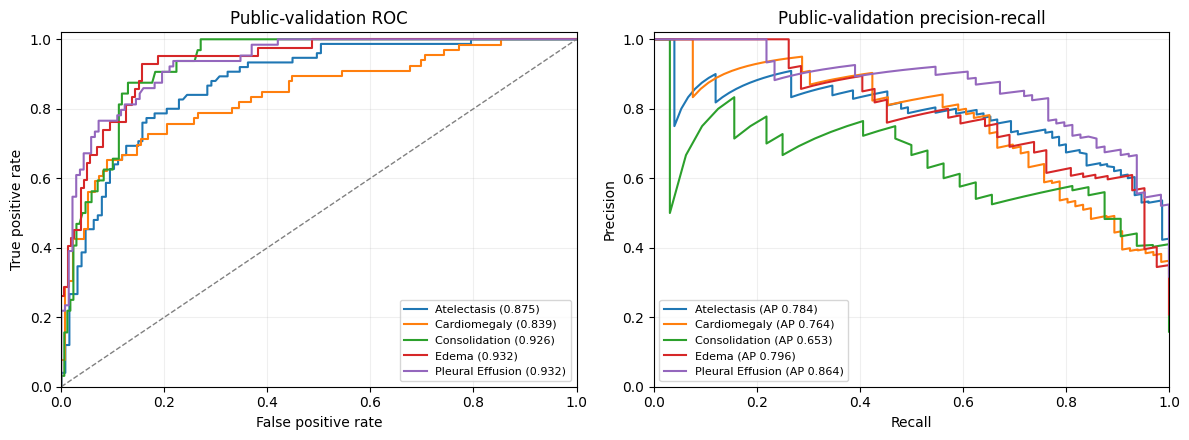

In [26]:
# Plot the public-validation ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i, label in enumerate(LABELS):
    if len(np.unique(truth[:, i])) == 2:
        fpr, tpr, _ = roc_curve(truth[:, i], selected_probs[:, i])
        axes[0].plot(fpr, tpr, label=f'{label} ({selected_metrics.loc[label, "AUROC"]:.3f})')
    if truth[:, i].sum():
        precision, recall, _ = precision_recall_curve(truth[:, i], selected_probs[:, i])
        axes[1].plot(recall, precision, label=f'{label} (AP {selected_metrics.loc[label, "AP"]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Public-validation ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Public-validation precision-recall')
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(PLOTS / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


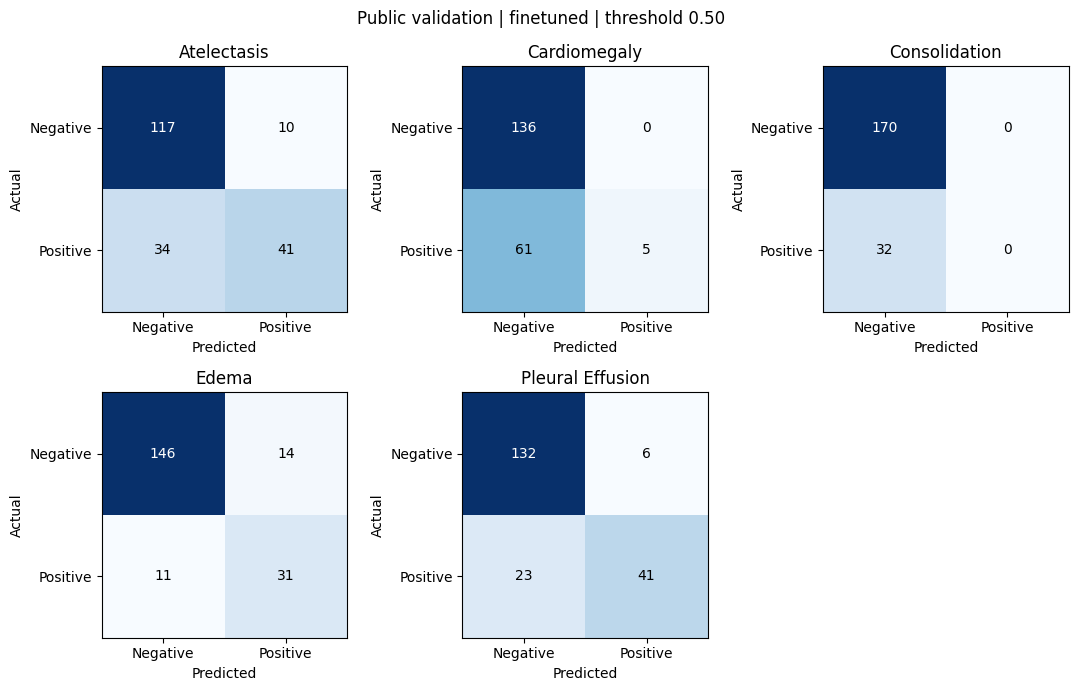

In [27]:
# Plot the five confusion matrices at the fixed reporting threshold
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for i, label in enumerate(LABELS):
    matrix = confusion_matrix(truth[:, i], selected_probs[:, i] >= THRESHOLD, labels=[0, 1])
    ax = axes.flat[i]
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            color = 'white' if matrix[row, column] > matrix.max() / 2 else 'black'
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center', color=color)
    ax.set(title=label, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1],
           xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes.flat[-1].axis('off')
fig.suptitle(f'Public validation | {selected_name} | threshold {THRESHOLD:.2f}')
fig.tight_layout()
fig.savefig(PLOTS / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


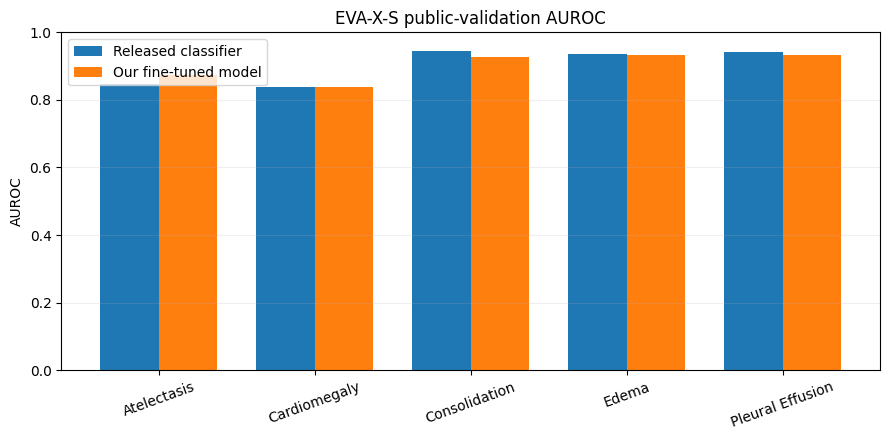

In [28]:
# Compare class-wise AUROC for the two evaluated checkpoints
comparison = pd.DataFrame({'Released classifier': reference_metrics.AUROC})
if RUN_TRAINING:
    comparison['Our fine-tuned model'] = selected_metrics.AUROC
ax = comparison.plot.bar(figsize=(9, 4.5), ylim=(0, 1), rot=20, width=0.75)
ax.set(title='EVA-X-S public-validation AUROC', xlabel='', ylabel='AUROC')
ax.grid(axis='y', alpha=0.2)
ax.figure.tight_layout()
ax.figure.savefig(RESULTS / 'class_auroc.png', dpi=180)
plt.show()
plt.close(ax.figure)


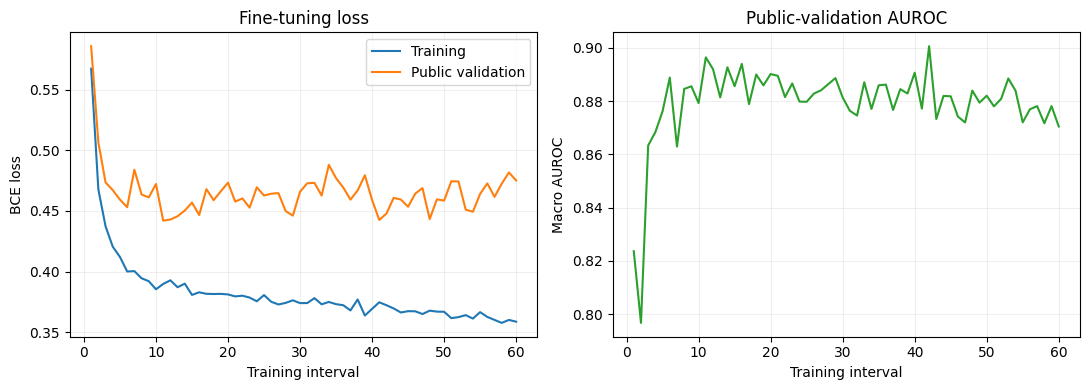

In [29]:
# Plot learning curves
if RUN_TRAINING:
    history = pd.read_csv(RESULTS / 'finetuned' / 'history.csv')
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history.interval, history.train_loss, label='Training')
    axes[0].plot(history.interval, history.public_val_loss, label='Public validation')
    axes[0].set(xlabel='Training interval', ylabel='BCE loss', title='Fine-tuning loss')
    axes[0].legend()
    axes[1].plot(history.interval, history.public_val_AUROC, color='tab:green')
    axes[1].set(xlabel='Training interval', ylabel='Macro AUROC', title='Public-validation AUROC')
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(RESULTS / 'finetuned' / 'learning_curves.png', dpi=180)
    plt.show()
    plt.close(fig)


In [30]:
# Save the timing, software versions, and source references
timing = dict(setup_and_reference_seconds=setup_and_reference_seconds,
              checkpoint_load_seconds=checkpoint_load_seconds, reference_inference_seconds=reference_seconds,
              training_stage_wall_seconds=training_wall_seconds, total_wall_seconds=time.time()-RUN_STARTED)
if RUN_TRAINING:
    timing.update(json.loads((RESULTS / 'finetuned' / 'training_summary.json').read_text()))
(RESULTS / 'timing.json').write_text(json.dumps(timing, indent=2))
versions = {name: metadata.version(name) for name in ['torch', 'torchvision', 'timm', 'einops',
             'pandas', 'numpy', 'scikit-learn', 'huggingface_hub']}
versions['GPUs'] = [torch.cuda.get_device_name(i) for i in range(GPU_COUNT)]
(RESULTS / 'environment.json').write_text(json.dumps(versions, indent=2))
sources = [
    'https://www.nature.com/articles/s41746-025-02032-z',
    f'https://github.com/hustvl/EVA-X/tree/{REPO_COMMIT}',
    f'https://huggingface.co/MapleF/eva_x/tree/{HF_REVISION}',
]
(RESULTS / 'sources.txt').write_text('\n'.join(sources) + '\n')
(RESULTS / 'README.md').write_text(
    'EVA-X-S on CheXpert\n\nReference metrics evaluate the released classifier. '
    'Finetuned metrics evaluate our full encoder/head run, if enabled. '
    'Both use the public validation set. See config.json, protocol.json, '
    'environment.json, timing.json and sources.txt for reproduction details. '
    'Training duration is recorded in short intervals, not full-data epochs.\n')
print(f'Total elapsed: {timing["total_wall_seconds"]/60:.1f} minutes')
print('Saved results:', RESULTS)


Total elapsed: 70.2 minutes
Saved results: /kaggle/working/eva_x_s_chexpert_results/seed14
